# Wildlife strike reports: exploratory analysis

We explore the data, missing values, trends, airports, animals, flight phases and aircraft damage. These are counts of **reports**, not risk per flight.

In [40]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from IPython.display import display

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 80)
DATA_PATH = Path("data") / "database.csv"
df = pd.read_csv(DATA_PATH, low_memory=False)
print(f"Loaded {len(df):,} rows and {len(df.columns)} columns from {DATA_PATH}.")
display(df.head())

Loaded 174,104 rows and 66 columns from data\database.csv.


,Record ID,Incident Year,Incident Month,Incident Day,Operator ID,Operator,Aircraft,Aircraft Type,Aircraft Make,Aircraft Model,Aircraft Mass,Engine Make,Engine Model,Engines,Engine Type,Engine1 Position,Engine2 Position,Engine3 Position,Engine4 Position,Airport ID,Airport,State,FAA Region,Warning Issued,Flight Phase,Visibility,Precipitation,Height,Speed,Distance,Species ID,Species Name,Species Quantity,Flight Impact,Fatalities,Injuries,Aircraft Damage,Radome Strike,Radome Damage,Windshield Strike,Windshield Damage,Nose Strike,Nose Damage,Engine1 Strike,Engine1 Damage,Engine2 Strike,Engine2 Damage,Engine3 Strike,Engine3 Damage,Engine4 Strike,Engine4 Damage,Engine Ingested,Propeller Strike,Propeller Damage,Wing or Rotor Strike,Wing or Rotor Damage,Fuselage Strike,Fuselage Damage,Landing Gear Strike,Landing Gear Damage,Tail Strike,Tail Damage,Lights Strike,Lights Damage,Other Strike,Other Damage
0,127128,1990,1,1,DAL,DELTA AIR LINES,B-757-200,A,148,26,4.0,34.0,40,2.0,D,1,1.0,NaN,NaN,KCVG,CINCINNATI/NORTHERN KENTUCKY INTL ARPT,KY,ASO,NaN,CLIMB,NaN,NaN,NaN,NaN,NaN,NE1,GULL,1,NaN,NaN,NaN,1,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,1,0,0,0,0
1,129779,1990,1,1,HAL,HAWAIIAN AIR,DC-9,A,583,90,4.0,34.0,10,2.0,D,5,5.0,NaN,NaN,PHLI,LIHUE ARPT,HI,AWP,NaN,TAKEOFF RUN,NaN,NaN,0.0,NaN,0.0,ZZ201,HOUSE SPARROW,1,NaN,NaN,NaN,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0
2,129780,1990,1,2,UNK,UNKNOWN,UNKNOWN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,PHLI,LIHUE ARPT,HI,AWP,NaN,NaN,NaN,NaN,NaN,NaN,0.0,R1101,BARN OWL,1,NaN,NaN,NaN,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
3,2258,1990,1,3,MIL,MILITARY,A-10A,A,345,NaN,3.0,22.0,NaN,2.0,D,NaN,NaN,NaN,NaN,KMYR,MYRTLE BEACH INTL,SC,ASO,NaN,APPROACH,DAY,NaN,200.0,138.0,NaN,UNKBM,UNKNOWN MEDIUM BIRD,1,NaN,NaN,NaN,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0
4,2257,1990,1,3,MIL,MILITARY,F-16,A,561,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,KJAX,JACKSONVILLE INTL,FL,ASO,NaN,CLIMB,DAY,NaN,100.0,200.0,NaN,ZX,FINCH,1,NaN,NaN,NaN,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0


## Data structure and quality

We check data types, missing values and duplicates. A repeated ID does not always mean a repeated row. Missing values are not filled with zero.

In [41]:
quality = pd.DataFrame({
    "type": df.dtypes.astype(str),
    "missing": df.isna().sum(),
    "missing (%)": df.isna().mean().mul(100).round(2),
    "unique values": df.nunique(),
}).sort_values("missing (%)", ascending=False)
display(quality)
print(f"Duplicate rows: {df.duplicated().sum():,}")
print(f"Repeated non-empty Record IDs: {df['Record ID'].dropna().duplicated().sum():,}")
display(df.describe(include="all").T)

,type,missing,missing (%),unique values
Injuries,float64,173875,99.87,7
Fatalities,float64,173539,99.68,5
Engine4 Position,float64,171012,98.22,4
Engine3 Position,str,162445,93.30,5
Speed,float64,102846,59.07,268
...,...,...,...,...
Tail Damage,int64,0,0.00,2
Lights Strike,int64,0,0.00,2
Lights Damage,int64,0,0.00,2
Other Strike,int64,0,0.00,2


Duplicate rows: 0
Repeated non-empty Record IDs: 0


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Record ID,174104.0,NaN,NaN,NaN,241204.036915,94013.682213,1000.0,205411.75,249102.5,322592.25,367445.0
Incident Year,174104.0,NaN,NaN,NaN,2006.036392,6.747708,1990.0,2001.0,2007.0,2012.0,2015.0
Incident Month,174104.0,NaN,NaN,NaN,7.17184,2.790152,1.0,5.0,8.0,9.0,12.0
Incident Day,174104.0,NaN,NaN,NaN,15.712264,8.799405,1.0,8.0,16.0,23.0,31.0
Operator ID,174104,539,UNK,39540,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...
Tail Damage,174104.0,NaN,NaN,NaN,0.004176,0.064485,0.0,0.0,0.0,0.0,1.0
Lights Strike,174104.0,NaN,NaN,NaN,0.005962,0.076983,0.0,0.0,0.0,0.0,1.0
Lights Damage,174104.0,NaN,NaN,NaN,0.004216,0.064793,0.0,0.0,0.0,0.0,1.0
Other Strike,174104.0,NaN,NaN,NaN,0.090727,0.287222,0.0,0.0,0.0,0.0,1.0


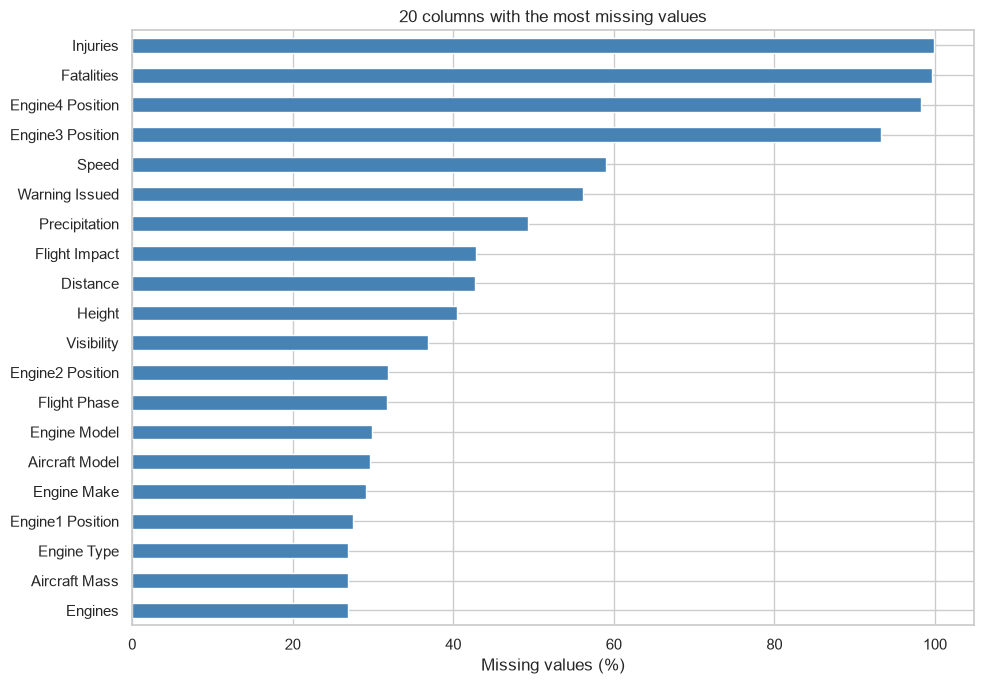

In [42]:
fig, ax = plt.subplots(figsize=(10, 7))
quality.head(20).sort_values("missing (%)")["missing (%)"].plot.barh(ax=ax, color="steelblue")
ax.set(title="20 columns with the most missing values", xlabel="Missing values (%)", ylabel="")
plt.tight_layout()
plt.show()

## Dates and trends

We combine the date columns without changing the original data. Invalid dates are treated as missing. The first and last years may be incomplete.

Missing or invalid dates: 0
Date range: 1990-01-01 00:00:00 to 2015-09-30 00:00:00


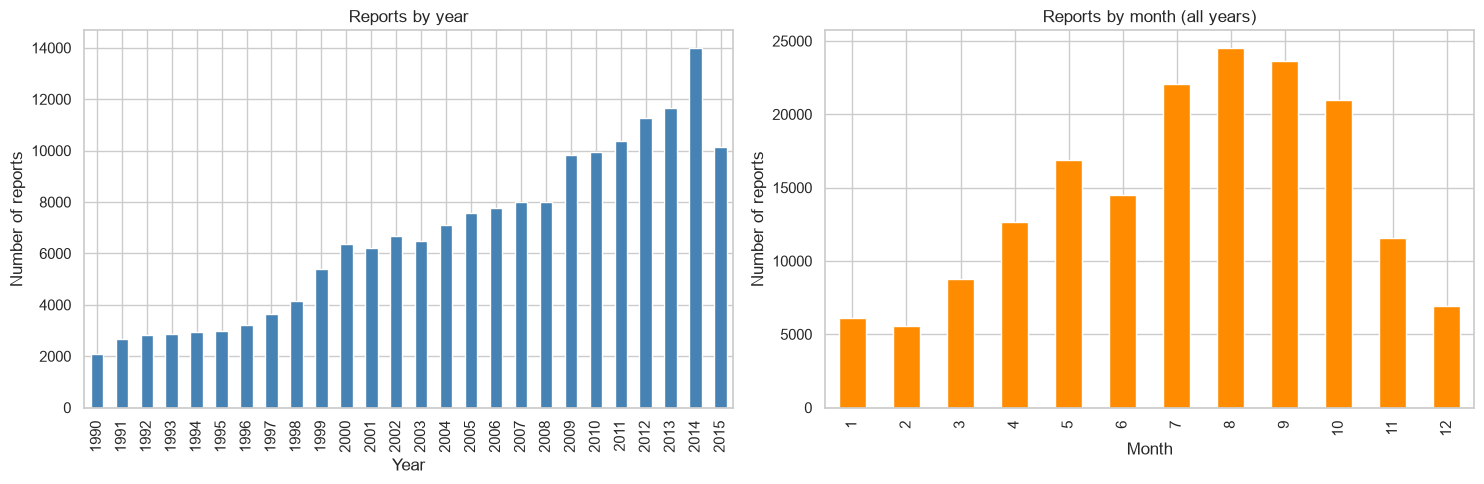

In [43]:
dates = pd.to_datetime(
    df[["Incident Year", "Incident Month", "Incident Day"]].rename(columns={
        "Incident Year": "year", "Incident Month": "month", "Incident Day": "day"
    }),
    errors="coerce",
)
print(f"Missing or invalid dates: {dates.isna().sum():,}")
print(f"Date range: {dates.min()} to {dates.max()}")
yearly = dates.dt.year.value_counts().sort_index()
monthly = dates.dt.month.value_counts().reindex(range(1, 13), fill_value=0)
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
yearly.plot.bar(ax=axes[0], color="steelblue")
axes[0].set(title="Reports by year", xlabel="Year", ylabel="Number of reports")
monthly.plot.bar(ax=axes[1], color="darkorange")
axes[1].set(title="Reports by month (all years)", xlabel="Month", ylabel="Number of reports")
plt.tight_layout()
plt.show()

## Airports, animals and flight phases

The charts exclude missing values but keep labels such as `UNKNOWN`. Names are shown as they appear in the data.

Airport: 290 missing
Species Name: 80 missing
Flight Phase: 55,302 missing


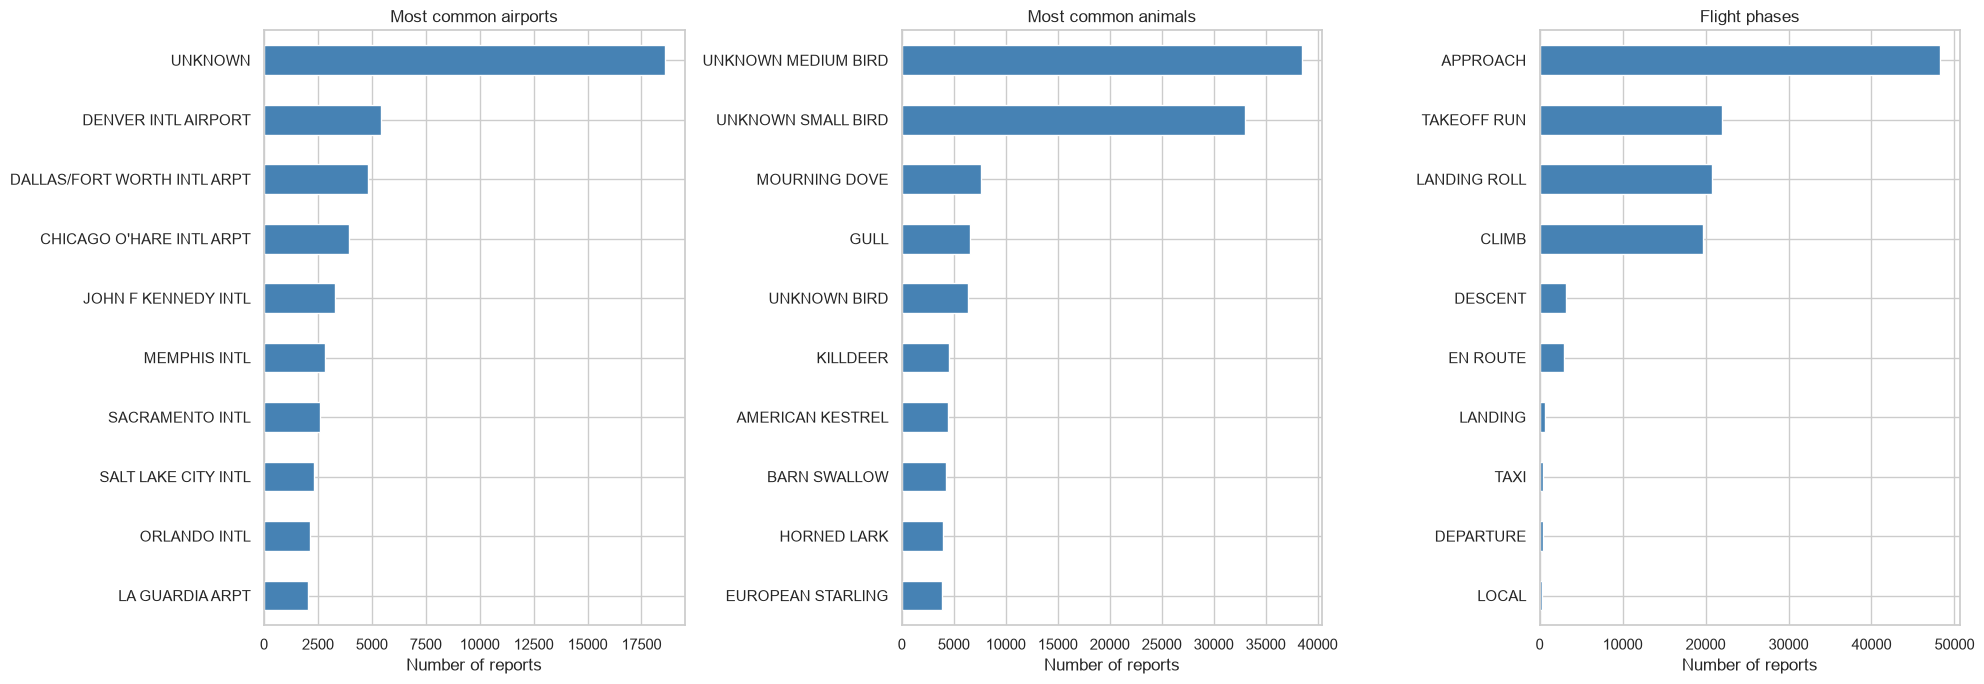

In [44]:
fig, axes = plt.subplots(1, 3, figsize=(20, 7))
for ax, column, title in zip(
    axes,
    ["Airport", "Species Name", "Flight Phase"],
    ["Most common airports", "Most common animals", "Flight phases"],
):
    counts = df[column].value_counts().head(10).sort_values()
    counts.plot.barh(ax=ax, color="steelblue")
    ax.set(title=title, xlabel="Number of reports", ylabel="")
    print(f"{column}: {df[column].isna().sum():,} missing")
plt.tight_layout()
plt.show()

## Unusual animals

We look at selected animal names, including turtles, alligators, snakes, armadillos and bears. We match full names so that a turtle-dove is not counted as a turtle. This is a selection of examples, not a complete list of unusual animals.

In [45]:
unusual_animals = [
    "TURTLE", "FLORIDA SOFT SHELL TURTLE", "EASTERN BOX TURTLE",
    "CHICKEN TURTLE", "COMMON SNAPPING TURTLE", "PAINTED TURTLE",
    "EASTERN MUD TURTLE", "ALLIGATOR SNAPPING TURTLE", "STRIPED MUD TURTLE",
    "GOPHER TORTOISE", "AMERICAN ALLIGATOR", "BULL SNAKE", "SNAKES",
    "NORTHERN WATER SNAKE", "EASTERN DIAMONDBACK RATTLESNAKE",
    "ARMADILLO", "AMERICAN BLACK BEAR",
]
unusual = df[df["Species Name"].isin(unusual_animals)].copy()
print(f"Reports for selected animals: {len(unusual):,}")
display(unusual["Species Name"].value_counts().rename_axis("Animal").to_frame("Reports"))
display(unusual[["Record ID", "Incident Year", "Incident Month", "Incident Day", "Species Name", "Airport", "State", "Flight Phase", "Aircraft Damage"]].sort_values(["Species Name", "Incident Year"]))

Reports for selected animals: 223


,Reports
Animal,
TURTLE,66
ARMADILLO,31
COMMON SNAPPING TURTLE,28
PAINTED TURTLE,24
AMERICAN ALLIGATOR,19
GOPHER TORTOISE,17
EASTERN BOX TURTLE,11
FLORIDA SOFT SHELL TURTLE,10
BULL SNAKE,5


,Record ID,Incident Year,Incident Month,Incident Day,Species Name,Airport,State,Flight Phase,Aircraft Damage
129211,324064,2012,5,3,ALLIGATOR SNAPPING TURTLE,ST LOUIS DOWNTOWN,IL,NaN,0
10921,103649,1994,4,13,AMERICAN ALLIGATOR,REMOTE_WATER,NaN,LANDING ROLL,1
13930,113198,1995,4,21,AMERICAN ALLIGATOR,SOUTHWEST FLORIDA INTL ARPT,FL,NaN,0
16307,113591,1995,12,19,AMERICAN ALLIGATOR,SOUTHWEST FLORIDA INTL ARPT,FL,NaN,0
16505,115919,1996,2,3,AMERICAN ALLIGATOR,SOUTHWEST FLORIDA INTL ARPT,FL,NaN,0
...,...,...,...,...,...,...,...,...,...
167945,362185,2015,6,4,TURTLE,WILL ROGERS WORLD ARPT,OK,NaN,0
167996,362199,2015,6,5,TURTLE,LA CROSSE MUNICIPAL AIRPORT,WI,NaN,0
168020,364041,2015,6,6,TURTLE,PHILADELPHIA INTL,PA,NaN,0
172196,365140,2015,8,26,TURTLE,TAMPA INTL,FL,NaN,0


## All turtle reports

We search the full dataset for names ending in `TURTLE` or `TORTOISE`. This includes the alligator snapping turtle but excludes turtle-doves. The table shows every matching report; `turtle_reports` keeps all original columns.

In [46]:
turtle_mask = df["Species Name"].str.contains(r"(?:^| )(?:TURTLE|TORTOISE)$", case=False, na=False)
turtle_reports = df.loc[turtle_mask].copy().sort_values(["Species Name", "Incident Year", "Record ID"])
print(f"Turtle reports in the full dataset: {len(turtle_reports):,}")
display(turtle_reports["Species Name"].value_counts().rename_axis("Animal").to_frame("Reports"))
turtle_columns = ["Record ID", "Incident Year", "Incident Month", "Incident Day", "Species Name", "Airport", "State", "Flight Phase", "Height", "Speed", "Distance", "Aircraft Damage"]
with pd.option_context("display.max_rows", None):
    display(turtle_reports[turtle_columns])

Turtle reports in the full dataset: 160


,Reports
Animal,
TURTLE,66
COMMON SNAPPING TURTLE,28
PAINTED TURTLE,24
GOPHER TORTOISE,17
EASTERN BOX TURTLE,11
FLORIDA SOFT SHELL TURTLE,10
ALLIGATOR SNAPPING TURTLE,1
CHICKEN TURTLE,1
EASTERN MUD TURTLE,1


,Record ID,Incident Year,Incident Month,Incident Day,Species Name,Airport,State,Flight Phase,Height,Speed,Distance,Aircraft Damage
129211,324064,2012,5,3,ALLIGATOR SNAPPING TURTLE,ST LOUIS DOWNTOWN,IL,NaN,NaN,NaN,0.0,0
21525,111567,1997,8,18,CHICKEN TURTLE,SOUTHWEST FLORIDA INTL ARPT,FL,NaN,NaN,NaN,0.0,0
22190,121408,1997,9,28,COMMON SNAPPING TURTLE,SOUTHWEST FLORIDA INTL ARPT,FL,NaN,NaN,NaN,0.0,0
24533,120431,1998,6,17,COMMON SNAPPING TURTLE,TETERBORO AIRPORT,NJ,TAKEOFF RUN,0.0,NaN,0.0,0
24362,120533,1998,5,27,COMMON SNAPPING TURTLE,TULSA INTL,OK,NaN,NaN,NaN,0.0,0
48179,214327,2002,7,16,COMMON SNAPPING TURTLE,TETERBORO AIRPORT,NJ,NaN,NaN,NaN,0.0,0
51618,218170,2002,11,21,COMMON SNAPPING TURTLE,FORT LAUDERDALE/HOLLYWOOD INTL,FL,TAXI,0.0,NaN,0.0,0
67704,229105,2005,5,27,COMMON SNAPPING TURTLE,FORT LAUDERDALE/HOLLYWOOD INTL,FL,NaN,NaN,NaN,0.0,0
91824,257992,2008,7,1,COMMON SNAPPING TURTLE,TETERBORO AIRPORT,NJ,NaN,NaN,NaN,0.0,0
99265,260683,2009,5,15,COMMON SNAPPING TURTLE,BALTIMORE/WASH INTL THURGOOD MARSHAL ARPT,MD,NaN,NaN,NaN,0.0,0


## Turtle reports over time and by state

We use all turtle reports, not the complete-case data used for the correlation matrix. We compare counts by year and state, then show how the state distribution changes over time. The yearly rate is turtle reports per 1,000 reports of any animal in the dataset, including reports with missing or unknown species. It is not a rate per flight. Changes in reporting, missing species and incomplete years can affect the trend; small counts can also fluctuate a lot.

Data date range: 1990-01-01 to 2015-09-30; the first and last years may be incomplete.


,Turtle reports,All reports,"Turtles per 1,000 reports"
Incident Year,,,
1990,0,2099,0.000000
1991,0,2672,0.000000
1992,1,2816,0.355114
1993,0,2849,0.000000
1994,0,2938,0.000000
1995,6,2989,2.007360
1996,2,3215,0.622084
1997,9,3651,2.465078
1998,5,4131,1.210361


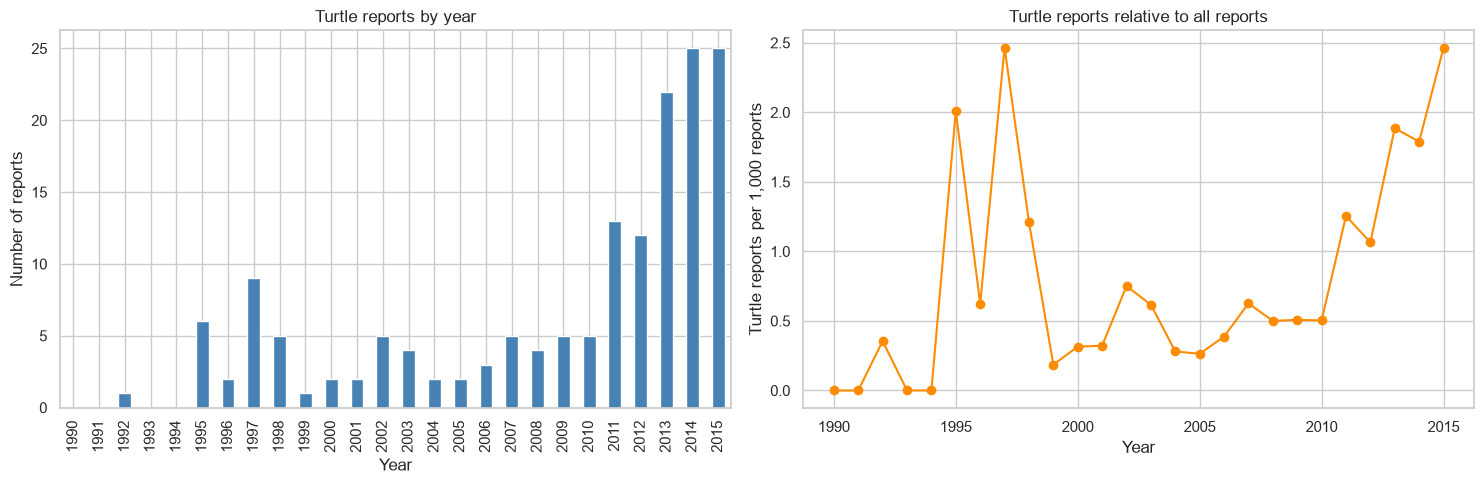

In [47]:
all_by_year = df.groupby("Incident Year").size().rename("All reports")
turtles_by_year = turtle_reports.groupby("Incident Year").size().reindex(all_by_year.index, fill_value=0).rename("Turtle reports")
yearly_turtles = pd.concat([turtles_by_year, all_by_year], axis=1)
yearly_turtles["Turtles per 1,000 reports"] = yearly_turtles["Turtle reports"] / yearly_turtles["All reports"] * 1_000
print(f"Data date range: {dates.min().date()} to {dates.max().date()}; the first and last years may be incomplete.")
display(yearly_turtles)
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
yearly_turtles["Turtle reports"].plot.bar(ax=axes[0], color="steelblue")
axes[0].set(title="Turtle reports by year", xlabel="Year", ylabel="Number of reports")
yearly_turtles["Turtles per 1,000 reports"].plot.line(ax=axes[1], marker="o", color="darkorange")
axes[1].set(title="Turtle reports relative to all reports", xlabel="Year", ylabel="Turtle reports per 1,000 reports")
plt.tight_layout()
plt.show()

Turtle reports without a state: 0


,Turtle reports
State,
FL,60
NJ,36
PA,11
OK,8
DC,7
NC,5
VA,5
AL,3
MI,3


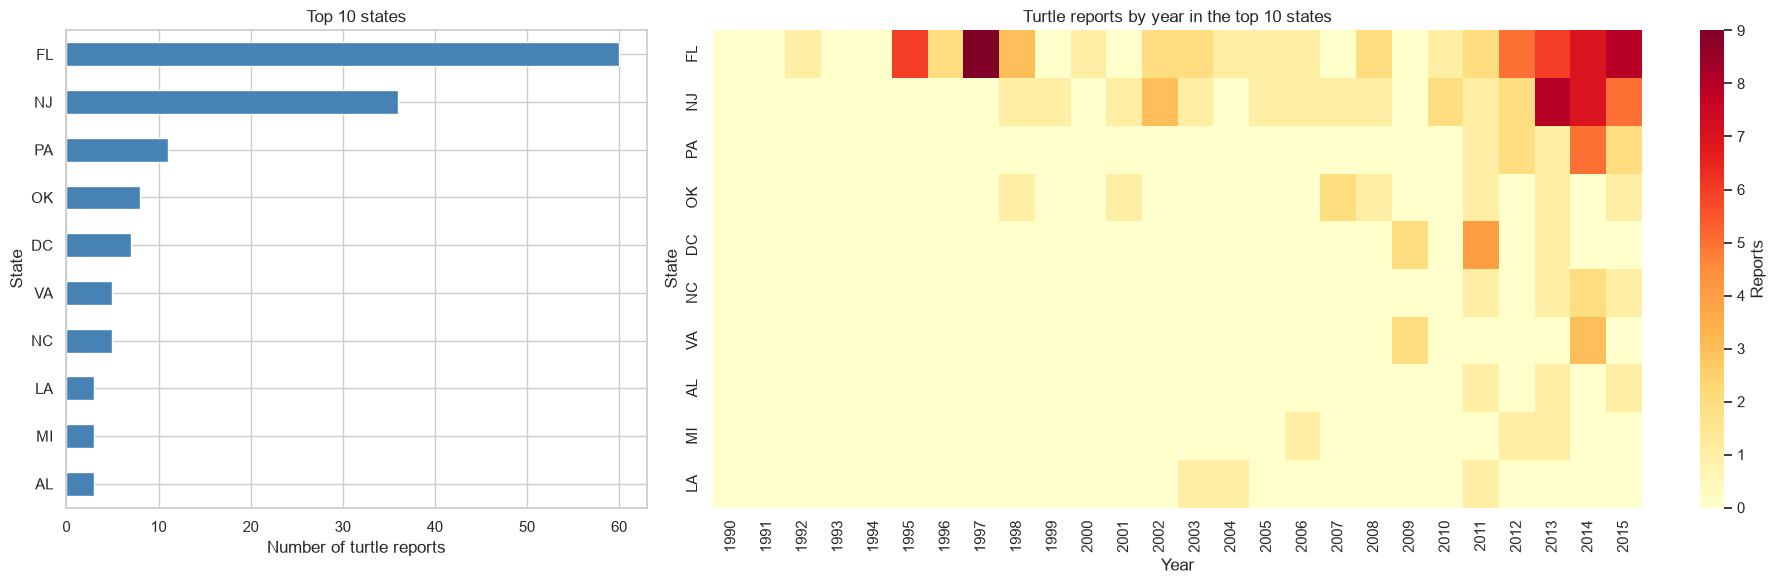

In [48]:
state_counts = turtle_reports["State"].value_counts().rename_axis("State").to_frame("Turtle reports")
print(f"Turtle reports without a state: {turtle_reports['State'].isna().sum():,}")
display(state_counts)
state_year = pd.crosstab(turtle_reports["State"], turtle_reports["Incident Year"]).reindex(columns=all_by_year.index, fill_value=0)
top_states = state_counts.head(10).index
fig, axes = plt.subplots(1, 2, figsize=(19, 6), gridspec_kw={"width_ratios": [1, 2]})
state_counts.head(10).sort_values("Turtle reports").plot.barh(y="Turtle reports", ax=axes[0], legend=False, color="steelblue")
axes[0].set(title="Top 10 states", xlabel="Number of turtle reports", ylabel="State")
sns.heatmap(state_year.loc[top_states], cmap="YlOrRd", ax=axes[1], cbar_kws={"label": "Reports"})
axes[1].set(title="Turtle reports by year in the top 10 states", xlabel="Year", ylabel="State")
plt.tight_layout()
plt.show()

## Turtle reports by airport

We count reports by airport name and compare the busiest airports over time. Names are used as recorded, so different names for the same airport are not combined. Counts are not adjusted for flight traffic.

Turtle reports without an airport: 0


,Turtle reports
Airport,
TETERBORO AIRPORT,26
SOUTHWEST FLORIDA INTL ARPT,22
ORLANDO SANFORD INTL ARPT,14
PHILADELPHIA INTL,10
MORRISTOWN MUNICIPAL ARPT,10
ORLANDO INTL,8
WILL ROGERS WORLD ARPT,7
WASHINGTON DULLES INTL ARPT,6
FORT LAUDERDALE/HOLLYWOOD INTL,4


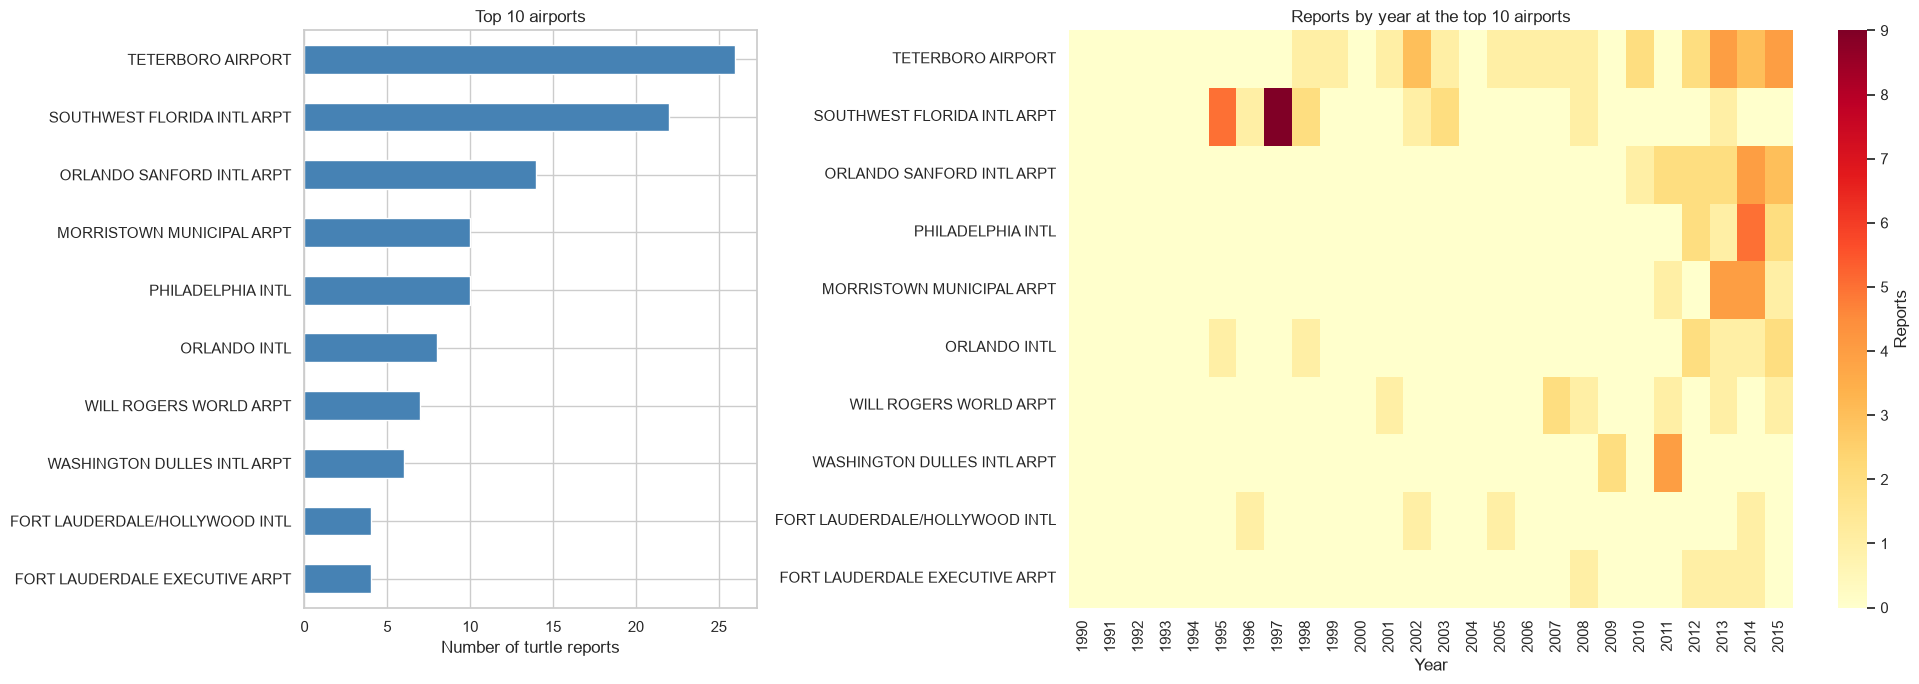

In [49]:
airport_counts = turtle_reports["Airport"].value_counts().rename_axis("Airport").to_frame("Turtle reports")
print(f"Turtle reports without an airport: {turtle_reports['Airport'].isna().sum():,}")
display(airport_counts.head(10))
airport_year = pd.crosstab(turtle_reports["Airport"], turtle_reports["Incident Year"]).reindex(columns=all_by_year.index, fill_value=0)
top_airports = airport_counts.head(10).index
fig, axes = plt.subplots(1, 2, figsize=(20, 7), gridspec_kw={"width_ratios": [1, 2]})
airport_counts.head(10).sort_values("Turtle reports").plot.barh(y="Turtle reports", ax=axes[0], legend=False, color="steelblue")
axes[0].set(title="Top 10 airports", xlabel="Number of turtle reports", ylabel="")
sns.heatmap(airport_year.loc[top_airports], cmap="YlOrRd", ax=axes[1], cbar_kws={"label": "Reports"})
axes[1].set(title="Reports by year at the top 10 airports", xlabel="Year", ylabel="")
plt.tight_layout()
plt.show()

## Turtle seasonality

We compare months across years. Grey cells are outside the dataset's date range, not zero reports. The first and last months may be partial; the data ends in September 2015. Counts can also be affected by changes in reporting.

Turtle reports with a missing month: 0


Incident Year,1990,1991,1992,1993,1994,1995,1996,1997,1998,1999,2000,2001,2002,2003,2004,2005,2006,2007,2008,2009,2010,2011,2012,2013,2014,2015
Incident Month,,,,,,,,,,,,,,,,,,,,,,,,,,
1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,2.0
4,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,2.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,4.0,0.0,1.0,2.0,4.0
5,0.0,0.0,0.0,0.0,0.0,2.0,0.0,1.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,1.0,2.0,3.0,0.0,2.0,1.0,6.0,4.0,4.0,8.0,7.0
6,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,1.0,0.0,1.0,0.0,1.0,1.0,0.0,0.0,1.0,0.0,0.0,2.0,1.0,3.0,3.0,2.0,7.0,5.0
7,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,2.0,1.0,0.0,0.0,2.0,5.0,2.0,1.0
8,0.0,0.0,0.0,0.0,0.0,1.0,0.0,3.0,0.0,0.0,0.0,1.0,0.0,2.0,1.0,0.0,0.0,1.0,0.0,0.0,2.0,0.0,1.0,4.0,2.0,3.0
9,0.0,0.0,1.0,0.0,0.0,0.0,0.0,2.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,2.0,1.0,3.0


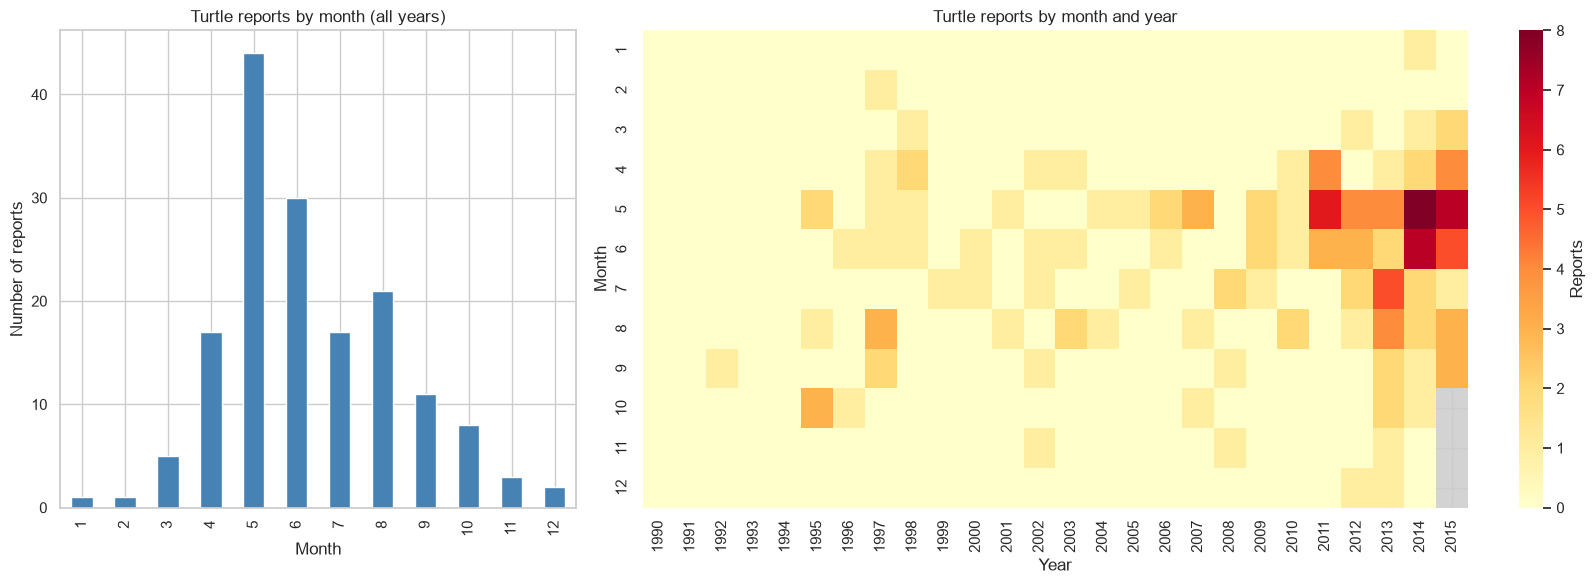

In [50]:
month_year = pd.crosstab(turtle_reports["Incident Month"], turtle_reports["Incident Year"]).reindex(index=range(1, 13), columns=all_by_year.index, fill_value=0).astype(float)
for year in month_year.columns:
    for month in month_year.index:
        period = pd.Period(year=int(year), month=int(month), freq="M")
        if period < dates.min().to_period("M") or period > dates.max().to_period("M"):
            month_year.loc[month, year] = float("nan")
print(f"Turtle reports with a missing month: {turtle_reports['Incident Month'].isna().sum():,}")
display(month_year)
fig, axes = plt.subplots(1, 2, figsize=(17, 6), gridspec_kw={"width_ratios": [1, 2]})
turtle_reports["Incident Month"].value_counts().reindex(range(1, 13), fill_value=0).plot.bar(ax=axes[0], color="steelblue")
axes[0].set(title="Turtle reports by month (all years)", xlabel="Month", ylabel="Number of reports")
axes[1].set_facecolor("lightgrey")
sns.heatmap(month_year, cmap="YlOrRd", ax=axes[1], cbar_kws={"label": "Reports"})
axes[1].set(title="Turtle reports by month and year", xlabel="Year", ylabel="Month")
plt.tight_layout()
plt.show()

## Turtle species over time

Each column shows the share of turtle reports assigned to each name that year. `TURTLE` is a general label, not a specific species. Blank years have no turtle reports; small yearly counts make shares unstable. The last year is incomplete.

Incident Year,1990,1991,1992,1993,1994,1995,1996,1997,1998,1999,2000,2001,2002,2003,2004,2005,2006,2007,2008,2009,2010,2011,2012,2013,2014,2015
Species Name,,,,,,,,,,,,,,,,,,,,,,,,,,
TURTLE,0,0,1,0,0,4,1,2,2,1,2,1,0,1,2,1,3,4,3,3,1,7,3,4,8,12
COMMON SNAPPING TURTLE,0,0,0,0,0,0,0,1,2,0,0,0,2,0,0,1,0,0,1,1,2,1,2,6,6,3
PAINTED TURTLE,0,0,0,0,0,0,0,0,0,0,0,1,2,1,0,0,0,1,0,0,0,1,2,5,6,5
GOPHER TORTOISE,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,2,2,3,5,4
EASTERN BOX TURTLE,0,0,0,0,0,0,1,3,0,0,0,0,1,0,0,0,0,0,0,1,1,2,0,2,0,0
FLORIDA SOFT SHELL TURTLE,0,0,0,0,0,2,0,2,1,0,0,0,0,1,0,0,0,0,0,0,0,0,2,2,0,0
ALLIGATOR SNAPPING TURTLE,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0
CHICKEN TURTLE,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
EASTERN MUD TURTLE,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0


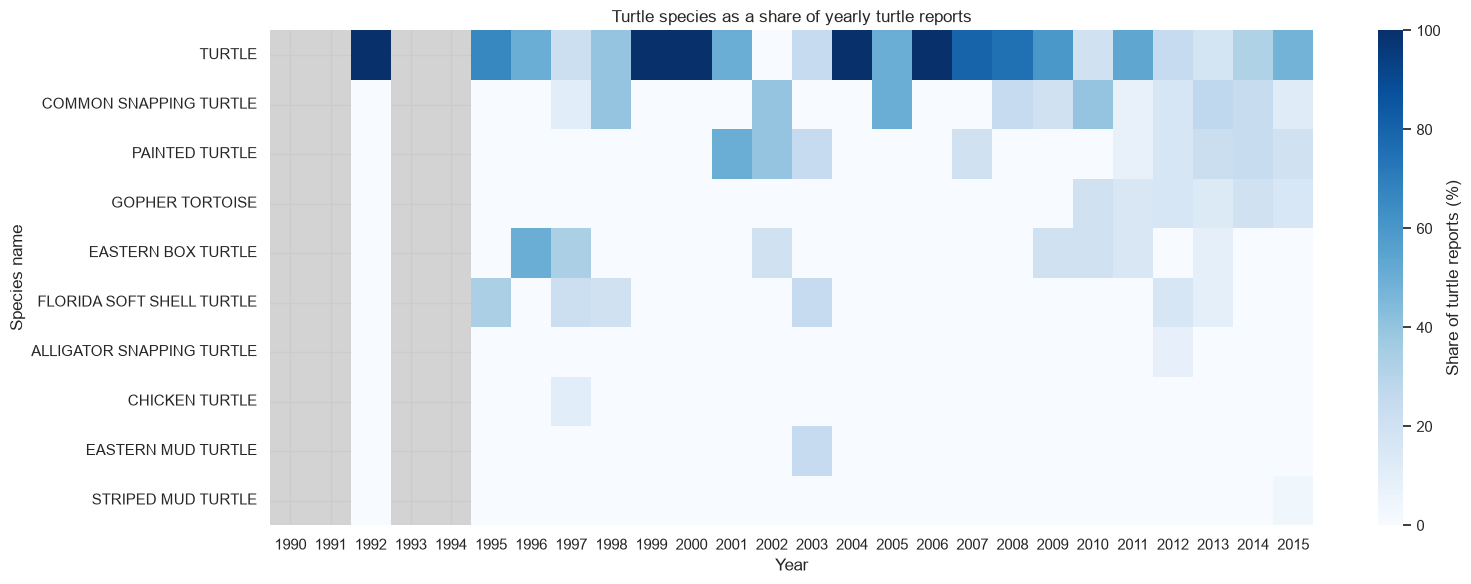

In [51]:
species_year = pd.crosstab(turtle_reports["Species Name"], turtle_reports["Incident Year"]).reindex(columns=all_by_year.index, fill_value=0)
species_year = species_year.loc[turtle_reports["Species Name"].value_counts().index]
species_share = species_year.div(species_year.sum(axis=0).replace(0, float("nan")), axis=1) * 100
display(species_year)
fig, ax = plt.subplots(figsize=(16, 6))
ax.set_facecolor("lightgrey")
sns.heatmap(species_share, cmap="Blues", vmin=0, vmax=100, ax=ax, cbar_kws={"label": "Share of turtle reports (%)"})
ax.set(title="Turtle species as a share of yearly turtle reports", xlabel="Year", ylabel="Species name")
plt.tight_layout()
plt.show()

## Data quality over time

For all reports, we track missing species names, names containing `UNKNOWN`, and missing flight phase. For turtle reports, we track missing flight phase, height, speed and distance, plus the general label `TURTLE`. Percentages use all reports in each respective group and year. Blank turtle years have no reports. Missing or generic names can hide turtle reports, and changes in data quality may affect the observed trend.

,Species name missing,Species name contains UNKNOWN,Flight phase missing
Incident Year,,,
1990,0.00000,49.690329,7.575036
1991,0.00000,51.908683,7.896707
1992,0.00000,50.923295,10.688920
1993,0.00000,48.999649,12.179712
1994,0.00000,50.476515,10.517359
1995,0.00000,54.499833,12.244898
1996,0.00000,55.676516,14.121306
1997,0.00000,55.491646,16.872090
1998,0.00000,51.658194,21.350763


,General TURTLE label,Flight phase missing,Height missing,Speed missing,Distance missing
Incident Year,,,,,
1990,NaN,NaN,NaN,NaN,NaN
1991,NaN,NaN,NaN,NaN,NaN
1992,100.000000,0.000000,0.000000,100.000000,0.0
1993,NaN,NaN,NaN,NaN,NaN
1994,NaN,NaN,NaN,NaN,NaN
1995,66.666667,83.333333,83.333333,100.000000,0.0
1996,50.000000,100.000000,100.000000,100.000000,0.0
1997,22.222222,100.000000,100.000000,100.000000,0.0
1998,40.000000,80.000000,80.000000,100.000000,0.0


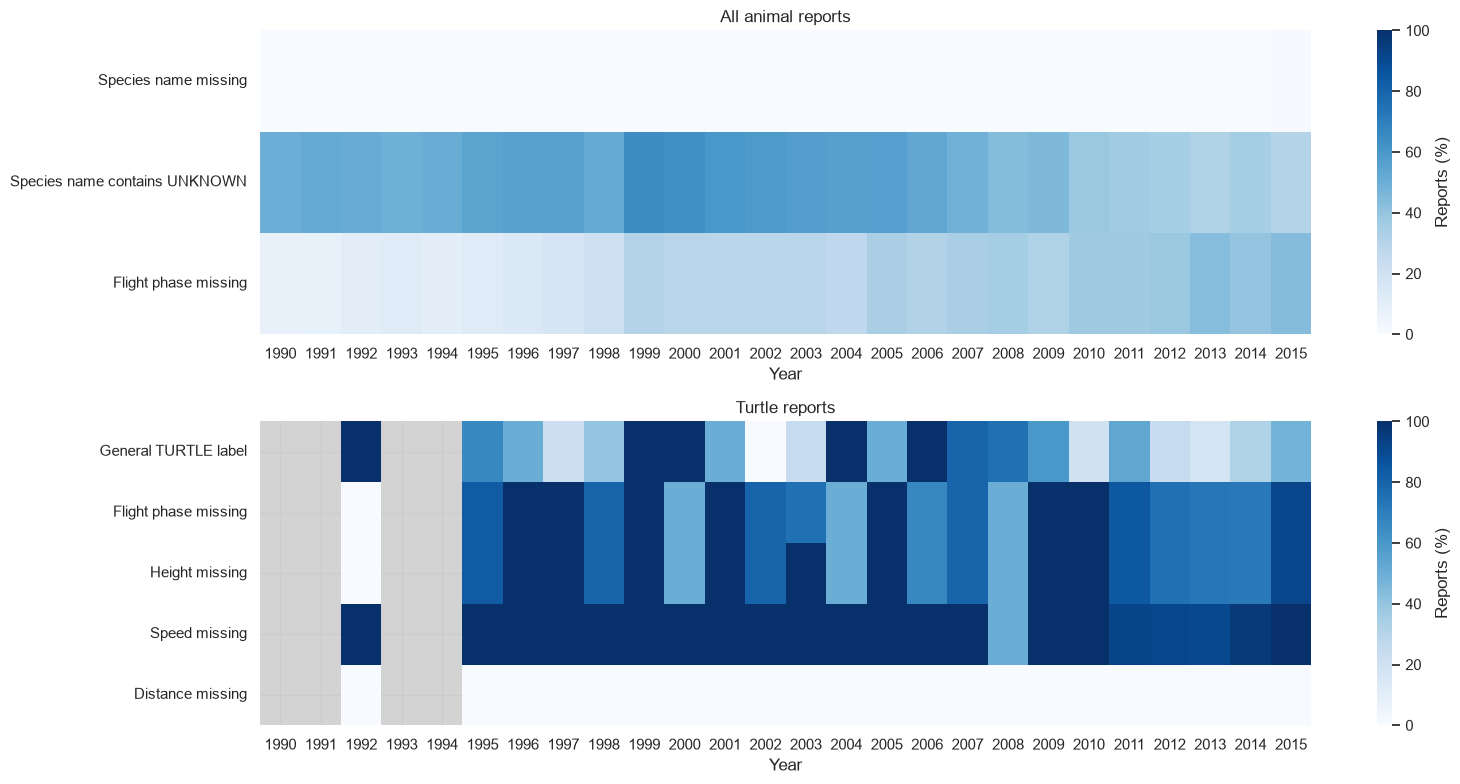

In [52]:
all_quality = pd.DataFrame({
    "Species name missing": df["Species Name"].isna(),
    "Species name contains UNKNOWN": df["Species Name"].str.contains("UNKNOWN", case=False, na=False),
    "Flight phase missing": df["Flight Phase"].isna(),
}).groupby(df["Incident Year"]).mean().mul(100).reindex(all_by_year.index)
turtle_quality = pd.DataFrame({
    "General TURTLE label": turtle_reports["Species Name"].eq("TURTLE"),
    "Flight phase missing": turtle_reports["Flight Phase"].isna(),
    "Height missing": turtle_reports["Height"].isna(),
    "Speed missing": turtle_reports["Speed"].isna(),
    "Distance missing": turtle_reports["Distance"].isna(),
}).groupby(turtle_reports["Incident Year"]).mean().mul(100).reindex(all_by_year.index)
display(all_quality)
display(turtle_quality)
fig, axes = plt.subplots(2, 1, figsize=(16, 8))
for ax, data, title in zip(axes, [all_quality, turtle_quality], ["All animal reports", "Turtle reports"]):
    ax.set_facecolor("lightgrey")
    sns.heatmap(data.T, cmap="Blues", vmin=0, vmax=100, ax=ax, cbar_kws={"label": "Reports (%)"})
    ax.set(title=title, xlabel="Year", ylabel="")
plt.tight_layout()
plt.show()

## Aircraft damage

We use only values 0 and 1 in `Aircraft Damage`. The damage rate excludes missing and other values. Differences between flight phases do not account for exposure or other factors.

Rows without a known 0/1 value: 0
Damage rate among known values: 8.6%


,Reports
Aircraft Damage,
0,159135
1,14969


,reports,with damage,damage rate
Flight Phase,,,
APPROACH,48275,4638,9.6%
TAKEOFF RUN,21953,2017,9.2%
LANDING ROLL,20762,1522,7.3%
CLIMB,19692,3197,16.2%
DESCENT,3174,639,20.1%
EN ROUTE,2989,1155,38.6%
LANDING,626,30,4.8%
TAXI,397,31,7.8%
DEPARTURE,369,13,3.5%


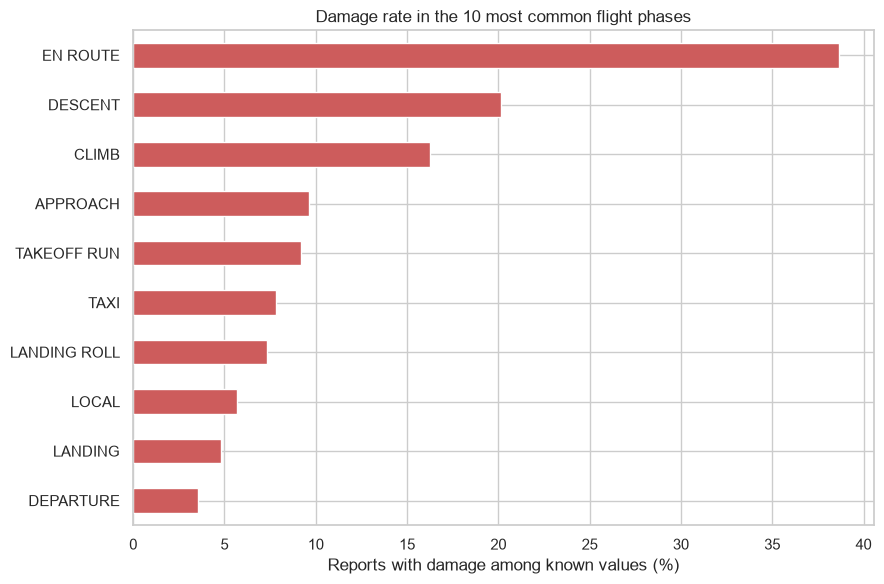

In [53]:
damage = pd.to_numeric(df["Aircraft Damage"], errors="coerce")
known_damage = damage.isin([0, 1])
print(f"Rows without a known 0/1 value: {(~known_damage).sum():,}")
print(f"Damage rate among known values: {damage[known_damage].mean():.1%}")
display(damage[known_damage].value_counts().rename_axis("Aircraft Damage").to_frame("Reports"))
phase_damage = (
    df.loc[known_damage, ["Flight Phase"]]
    .assign(damage=damage[known_damage])
    .groupby("Flight Phase")["damage"]
    .agg(["size", "sum", "mean"])
    .rename(columns={"size": "reports", "sum": "with damage", "mean": "damage rate"})
    .sort_values("reports", ascending=False)
)
display(phase_damage.style.format({"with damage": "{:.0f}", "damage rate": "{:.1%}"}))
fig, ax = plt.subplots(figsize=(9, 6))
phase_damage.head(10).sort_values("damage rate")["damage rate"].mul(100).plot.barh(ax=ax, color="indianred")
ax.set(title="Damage rate in the 10 most common flight phases", xlabel="Reports with damage among known values (%)", ylabel="")
plt.tight_layout()
plt.show()

## Numeric values

The summary uses available values without filling gaps with zero. Units and unusual values need to be checked against the data documentation.

In [54]:
numeric_columns = ["Height", "Speed", "Distance", "Fatalities", "Injuries"]
numeric = df[numeric_columns].apply(pd.to_numeric, errors="coerce")
display(numeric.describe(percentiles=[0.5, 0.9, 0.99]).T)
print("Missing numeric values:")
display(numeric.isna().sum().to_frame("missing"))

,count,mean,std,min,50%,90%,99%,max
Height,103677.0,831.032283,1803.650833,0.0,50.0,2800.0,9000.00,31300.0
Speed,71258.0,141.925622,46.905651,0.0,138.0,210.0,250.00,2500.0
Distance,99713.0,0.703738,3.464467,0.0,0.0,0.0,20.00,150.0
Fatalities,565.0,0.046018,0.435164,0.0,0.0,0.0,1.00,8.0
Injuries,229.0,1.746725,6.571239,1.0,1.0,2.0,6.44,100.0


Missing numeric values:


,missing
Height,70427
Speed,102846
Distance,74391
Fatalities,173539
Injuries,173875


## Correlation matrix: all complete reports

We compare height, speed and distance from the airport using all reports with values in `Height`, `Speed` and `Distance`. Other columns may still have missing values. Missing values may affect the results. Correlation does not prove cause and effect. Check the meaning and units of these fields against the source documentation.

Complete rows: 32,832 of 174,104.


,Height,Speed,Distance from airport
Height,1.000000,0.689267,0.850810
Speed,0.689267,1.000000,0.615801
Distance from airport,0.850810,0.615801,1.000000


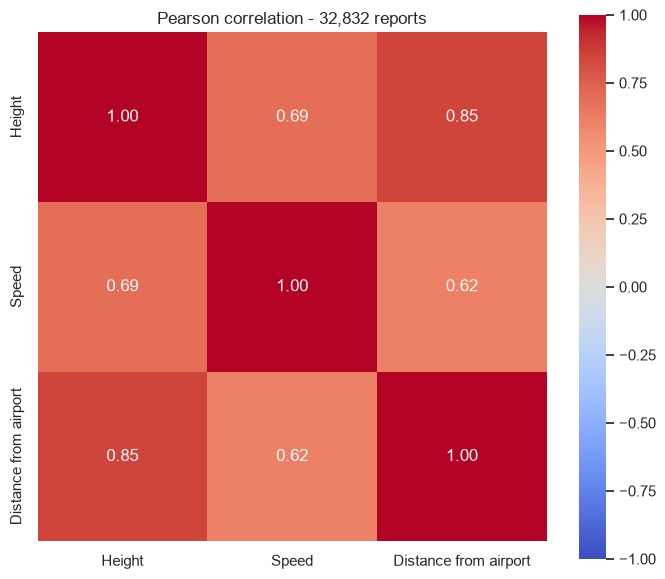

In [55]:
correlation_columns = ["Height", "Speed", "Distance"]
complete = df[correlation_columns].apply(pd.to_numeric, errors="coerce").dropna()
complete_values = complete.rename(columns={"Distance": "Distance from airport"})
correlation = complete_values.corr(method="pearson")
print(f"Complete rows: {len(complete_values):,} of {len(df):,}.")
display(correlation)
fig, ax = plt.subplots(figsize=(7, 6))
sns.heatmap(correlation, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, center=0, square=True, ax=ax)
ax.set_title(f"Pearson correlation - {len(complete_values):,} reports")
plt.tight_layout()
plt.show()

### All complete reports

`complete_values` contains the three numeric columns used in the correlation matrix. `complete_records` contains the same reports with all original columns; columns outside the three selected fields may have missing values.

In [56]:
complete_records = df.loc[complete_values.index].copy()
print(f"Selected reports: {len(complete_records):,}")
print("Missing values in the three selected numeric columns:")
display(complete_values.isna().sum().to_frame("Missing values"))
display(complete_values.head())
display(complete_records.head())

Selected reports: 32,832
Missing values in the three selected numeric columns:


,Missing values
Height,0
Speed,0
Distance from airport,0


,Height,Speed,Distance from airport
12,0.0,100.0,0.0
14,0.0,140.0,0.0
16,0.0,160.0,0.0
27,225.0,142.0,0.0
41,0.0,120.0,0.0


,Record ID,Incident Year,Incident Month,Incident Day,Operator ID,Operator,Aircraft,Aircraft Type,Aircraft Make,Aircraft Model,Aircraft Mass,Engine Make,Engine Model,Engines,Engine Type,Engine1 Position,Engine2 Position,Engine3 Position,Engine4 Position,Airport ID,Airport,State,FAA Region,Warning Issued,Flight Phase,Visibility,Precipitation,Height,Speed,Distance,Species ID,Species Name,Species Quantity,Flight Impact,Fatalities,Injuries,Aircraft Damage,Radome Strike,Radome Damage,Windshield Strike,Windshield Damage,Nose Strike,Nose Damage,Engine1 Strike,Engine1 Damage,Engine2 Strike,Engine2 Damage,Engine3 Strike,Engine3 Damage,Engine4 Strike,Engine4 Damage,Engine Ingested,Propeller Strike,Propeller Damage,Wing or Rotor Strike,Wing or Rotor Damage,Fuselage Strike,Fuselage Damage,Landing Gear Strike,Landing Gear Damage,Tail Strike,Tail Damage,Lights Strike,Lights Damage,Other Strike,Other Damage
12,113914,1990,1,11,BUS,BUSINESS,HAWKER-SDLY HS125,A,443,30,3.0,NaN,NaN,2.0,B,5,5.0,NaN,NaN,KJWN,JOHN C TUNE ARPT,TN,ASO,NaN,TAKEOFF RUN,NIGHT,NaN,0.0,100.0,0.0,1G11,WHITE-TAILED DEER,2-10,PRECAUTIONARY LANDING,NaN,NaN,1,0,0,0,0,0,0,1,1,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0
14,102248,1990,1,11,SWA,SOUTHWEST AIRLINES,B-737-300,A,148,24,4.0,10.0,1,2.0,D,1,1.0,NaN,NaN,KMSY,LOUIE ARMSTRONG NEW ORLEANS INTL ARPT,LA,ASW,Y,TAKEOFF RUN,DAY,NaN,0.0,140.0,0.0,O2111,ROCK PIGEON,2-10,PRECAUTIONARY LANDING,NaN,NaN,1,0,0,0,0,0,0,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
16,2260,1990,1,13,MIL,MILITARY,E-6,A,148,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,PHNL,HONOLULU INTL ARPT,HI,AWP,NaN,LANDING ROLL,NaN,NaN,0.0,160.0,0.0,UNKBM,UNKNOWN MEDIUM BIRD,2-10,NaN,NaN,NaN,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0
27,5206,1990,1,23,MIL,MILITARY,F-15C,A,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,KVPS,EGLIN AIR FORCE BASE/DESTIN-FORT WALTON BEACH ...,FL,ASO,Y,TAKEOFF RUN,DAY,NaN,225.0,142.0,0.0,UNKBM,UNKNOWN MEDIUM BIRD,1,NaN,NaN,NaN,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
41,1610,1990,2,8,MIL,MILITARY,C-135,A,148,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,PHLI,LIHUE ARPT,HI,AWP,NaN,TAKEOFF RUN,DAY,NaN,0.0,120.0,0.0,N6,SANDPIPER,1,NaN,NaN,NaN,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0


## Next steps

- Find the source documentation, field definitions, units and reporting rules.
- Check whether each year is complete, especially the first and last.
- Add flight counts before comparing risk across airports or years.
- Check how missing values and `UNKNOWN` categories affect the results.